In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Loading Data

In [2]:
col = ["num_preg", "plasma_glucose_conc", "D_blood_pressure", "skin_fold_thickness", "serum_insulin", "body_mass_index", "pedigree_func", "age", "diabetes"]
diabetes_data = pd.read_csv("https://raw.githubusercontent.com/dphi-official/ML_Models/master/Performance_Evaluation/diabetes.txt", names = col)

In [3]:
diabetes_data.head()

,num_preg,plasma_glucose_conc,D_blood_pressure,skin_fold_thickness,serum_insulin,body_mass_index,pedigree_func,age,diabetes
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Sepzrating input variables and output variables

In [4]:
x = diabetes_data.drop('diabetes',axis = 1)
y = diabetes_data.diabetes

In [5]:
# Splitting data into test set and trainin set
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 42)

Developing a Neural Network Model

In [6]:
from sklearn.neural_network import MLPClassifier
mlp = MLPClassifier(max_iter = 1000)
mlp.fit(x_train,y_train)

MLPClassifier(max_iter=1000)

In [8]:
y_pred = mlp.predict(x_test)

Performance Evaluation

In [9]:
from sklearn.metrics import confusion_matrix
conf = confusion_matrix(y_test,y_pred)
conf = pd.DataFrame(conf,columns = ['True Positive','False Positive'],index = ['False Negative','True Negative'])
conf

,True Positive,False Positive
False Negative,78,21
True Negative,22,33


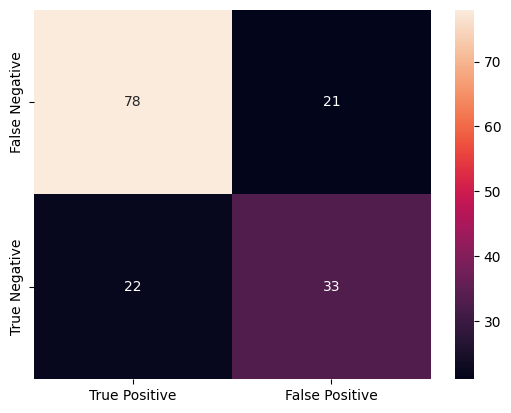

In [10]:
sns.heatmap(conf,annot = True)
plt.show()

In [11]:
# Accuracy of a model
from sklearn.metrics import accuracy_score
print("The accuracy score for our model is ",accuracy_score(y_test,y_pred))

The accuracy score for our model is  0.7207792207792207


Sensitivity

```
\begin{align}

Sensitivity = \frac{TP}{TP + FN}

\end{align}
```



In [12]:
from sklearn.metrics import recall_score
print("The sensitivity of our model is ",recall_score(y_test,y_pred))

The sensitivity of our model is  0.6


Precision

In [ ]:
from sklearn.metrics import precision_score
print("The precision of our model is ",precision_score(y_test,y_pred))

The precision of our model is  0.6


Imbalanced Datasets

In [ ]:
diabetes_data.diabetes.value_counts()

,count
diabetes,
0,500
1,268


Matthews Correlation Coefficient

In [ ]:
from sklearn.metrics import matthews_corrcoef
print("The Matthew's correlation coefficient is ",matthews_corrcoef(y_test,y_pred))

The Matthew's correlation coefficient is  0.3256609369751915


F1 Score

In [ ]:
from sklearn.metrics import f1_score
print("The F1 score is ",f1_score(y_test,y_pred))

The F1 score is  0.54


Area Under the Curve

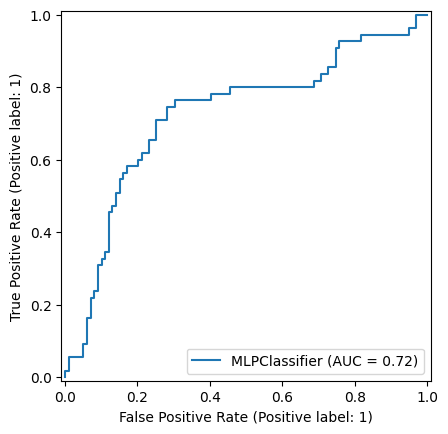

In [13]:
from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_estimator(mlp,x_test,y_test)
plt.show()

Example 2

In [ ]:
wine = pd.read_csv("https://raw.githubusercontent.com/dphi-official/ML_Models/master/Performance_Evaluation/winequality.csv", sep=";")

In [ ]:
wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


Separate Input and Output Variables

In [ ]:
x = wine.drop('quality',axis = 1)
y = wine.quality

In [ ]:
# Split into training and testing set
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 3)

Fitting a Linear Model

In [ ]:
from sklearn.linear_model import LinearRegression
lin = LinearRegression()
lin.fit(x_train,y_train)

LinearRegression()

In [ ]:
y_pred = lin.predict(x_test)

Performance Measurement

In [ ]:
from sklearn.metrics import mean_absolute_error
print("The mean absolute error is ",mean_absolute_error(y_test,y_pred))

The mean absolute error is  0.5972358558776462


Mean Squared Error

In [ ]:
from sklearn.metrics import mean_squared_error
print("The mean squared error is ",mean_squared_error(y_test,y_pred))

The mean squared error is  0.5906658099548044


Root Mean Squared Error

In [ ]:
from sklearn.metrics import root_mean_squared_error
print("The root mean squared error is ",root_mean_squared_error(y_test,y_pred))

The root mean squared error is  0.7685478579469235


R Squared

In [ ]:
from sklearn.metrics import r2_score
print("The r2 score is ",r2_score(y_test,y_pred))

The r2 score is  0.2832037191111062


Cross Validation

1. Kfold

In [15]:
from sklearn.model_selection import cross_validate
scores = cross_validate(mlp,x,y,cv = 10,scoring = ['accuracy','precision','recall'])
scores

{'fit_time': array([0.45766497, 0.2417202 , 0.32226133, 0.3009119 , 0.21103334,
        0.26807237, 0.2399621 , 0.43668175, 0.29885125, 0.29867959]),
 'score_time': array([0.00790477, 0.0073657 , 0.00749874, 0.01132178, 0.01018858,
        0.01018572, 0.01049781, 0.01078343, 0.01057291, 0.01052761]),
 'test_accuracy': array([0.61038961, 0.72727273, 0.7012987 , 0.67532468, 0.7012987 ,
        0.75324675, 0.71428571, 0.66233766, 0.68421053, 0.61842105]),
 'test_precision': array([0.44444444, 0.875     , 0.55882353, 0.53571429, 0.59090909,
        0.72222222, 0.69230769, 0.51515152, 0.75      , 0.44444444]),
 'test_recall': array([0.44444444, 0.25925926, 0.7037037 , 0.55555556, 0.48148148,
        0.48148148, 0.33333333, 0.62962963, 0.11538462, 0.46153846])}

Evaluating the metrics

In [16]:
print(f'The mean accuracy is {scores["test_accuracy"].mean()}')
print(f'The mean precision is {scores["test_precision"].mean()}')
print(f'The mean recall is {scores["test_recall"].mean()}')

The mean accuracy is 0.6848086124401914
The mean precision is 0.612901722460546
The mean recall is 0.4465811965811966


In [19]:
# To print out the scorers we can use
import sklearn.metrics as m
m.get_scorer_names()


['accuracy',
 'adjusted_mutual_info_score',
 'adjusted_rand_score',
 'average_precision',
 'balanced_accuracy',
 'completeness_score',
 'd2_absolute_error_score',
 'explained_variance',
 'f1',
 'f1_macro',
 'f1_micro',
 'f1_samples',
 'f1_weighted',
 'fowlkes_mallows_score',
 'homogeneity_score',
 'jaccard',
 'jaccard_macro',
 'jaccard_micro',
 'jaccard_samples',
 'jaccard_weighted',
 'matthews_corrcoef',
 'max_error',
 'mutual_info_score',
 'neg_brier_score',
 'neg_log_loss',
 'neg_mean_absolute_error',
 'neg_mean_absolute_percentage_error',
 'neg_mean_gamma_deviance',
 'neg_mean_poisson_deviance',
 'neg_mean_squared_error',
 'neg_mean_squared_log_error',
 'neg_median_absolute_error',
 'neg_negative_likelihood_ratio',
 'neg_root_mean_squared_error',
 'neg_root_mean_squared_log_error',
 'normalized_mutual_info_score',
 'positive_likelihood_ratio',
 'precision',
 'precision_macro',
 'precision_micro',
 'precision_samples',
 'precision_weighted',
 'r2',
 'rand_score',
 'recall',
 'recall

Leave one Out Technique

In [20]:
from sklearn.model_selection import LeaveOneOut
cv = cross_validate(mlp,x,y,cv = LeaveOneOut(),scoring = ['accuracy','roc_auc','precision','recall'])
cv

Streaming output truncated to the last 5000 lines.
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_scorer.py", line 139, in __call__
    score = scorer._score(
  File "/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_scorer.py", line 376, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/utils/_param_validation.py", line 213, in wrapper
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py", line 640, in roc_auc_score
    return _average_binary_score(
  File "/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_base.py", line 76, in _average_binary_score
    return binary_metric(y_true, y_score, sample_weight=sample_weight)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py", line 382, in _binary_roc_auc_score
    raise ValueError(
ValueError: Only one cl

{'fit_time': array([0.48319364, 0.43804479, 0.31695032, 0.57026839, 0.4419446 ,
        0.72184753, 0.33175492, 0.4151988 , 0.50661922, 0.21028733,
        0.74181199, 0.32006383, 0.45100713, 0.29380059, 0.3096168 ,
        0.49340248, 0.40803218, 0.27433372, 0.55635262, 0.26816273,
        0.4279139 , 0.28439093, 0.54323888, 0.3532536 , 0.32547021,
        0.57001638, 0.47555351, 0.61453748, 0.30061698, 0.45439649,
        0.5925808 , 0.42927647, 0.76899886, 0.47923923, 0.46188974,
        0.4789362 , 0.36915469, 0.51409006, 1.0623219 , 0.55197573,
        0.47463775, 0.53996634, 0.42501783, 0.59717274, 0.76645041,
        0.65136766, 0.26920795, 0.1663065 , 0.61995173, 0.4970603 ,
        0.36630917, 0.35529447, 1.04707837, 0.37700057, 0.6348083 ,
        0.43934178, 0.84499288, 0.39218402, 0.63694263, 0.67157459,
        0.24970865, 0.5502975 , 0.21145439, 0.28976512, 0.44100761,
        0.41338253, 0.68698239, 0.68410373, 0.56024051, 0.38695908,
        0.60852981, 0.43037105, 0.43

Hyperparameter Tuning

In [21]:
from sklearn.model_selection import GridSearchCV

In [22]:
crime = pd.read_csv("https://raw.githubusercontent.com/dphi-official/ML_Models/master/Performance_Evaluation/Standard%20Metropolitan%20Areas%20Data%20-%20train_data.csv")
train, test = train_test_split(crime)
x_train = train.drop('crime_rate', axis = 1)
y_train = train.crime_rate
x_test = test.drop('crime_rate', axis = 1)
y_test = test.crime_rate

Performance without Grid Search

In [23]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [24]:
from sklearn.metrics import mean_squared_error
print("The mean squared error is ",mean_squared_error(y_test,y_pred))

The mean squared error is  122.9443576761303


Performance with Grid Search

1. Define Parameter Space

In [35]:
param_space = {'fit_intercept':[True,False],'n_jobs':[-1,1,10,15],'copy_X':[True, False]}

In [36]:
grid = GridSearchCV(model,param_space,cv = 3)

In [37]:
grid.fit(x_train,y_train)

GridSearchCV(cv=3, estimator=LinearRegression(),
             param_grid={'copy_X': [True, False],
                         'fit_intercept': [True, False],
                         'n_jobs': [-1, 1, 10, 15]})

In [38]:
grid.best_estimator_

LinearRegression(n_jobs=-1)

In [39]:
grid.best_params_

{'copy_X': True, 'fit_intercept': True, 'n_jobs': -1}

In [41]:
model = LinearRegression(copy_X=True, fit_intercept=True, n_jobs=-1)

In [42]:
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

Model Evaluation

In [43]:
from sklearn.metrics import mean_squared_error
print("The mean squared error for the Tuned model is ",mean_squared_error(y_test,y_pred))

The mean squared error for the Tuned model is  122.9443576761303
